# 04 — Contextual-Completeness Error Diagnostic

RQ4: how are the completeness and validation status of composition, processing and testing information associated with out-of-fold prediction error?

This notebook does not test whether adding processing/testing information as model features would improve prediction — they're never used as predictors anywhere below. It's not making a causal claim that incomplete context *causes* higher error, and it isn't testing the incremental predictive value of any variable.

What it does test is whether the fixed, already-computed out-of-fold prediction errors from Notebook 03 (Random Forest as the primary diagnostic model, Gradient Boosting as a sensitivity check, dummy-mean as reference) are *associated* with three contextual-completeness dimensions: processing-identity status, test-condition status, and composition completeness.

Fixed before any result is seen, and never revisited afterward: the OOF predictions themselves (persisted by 03, no retraining here), the three dimensions analysed, the minimum-DOI support thresholds, and the models compared. No subgroup gets defined after seeing results.


## Imports

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "modelling" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from literature_pipeline.modelling import dataset_contract as dc
from literature_pipeline.modelling import modelling_lib as ml

# NOTE: this notebook is a thin experiment/analysis layer over modelling_lib.py.
# No modelling/CV/bootstrap logic is duplicated here -- error_subgroup_table,
# tie_safe_quantile_groups, and support_label all live in the shared library.

## Load the persisted OOF artifact and independently reload the corrected dataset

No retraining happens anywhere in this notebook. `oof_artifact` is exactly what 03 exported — fixed predictions, per target/model/fold. `df` is reloaded and corrected independently, the same pattern as 03 loading independently of 02, so this notebook doesn't depend on 03's in-memory state — it's reproducible from disk alone.


In [2]:
OOF_ARTIFACT_PATH = PROJECT_ROOT / "data" / "modelling_results" / "notebook03_oof_predictions.csv"
FINAL_DATASET_PATH = PROJECT_ROOT / "data" / "datasets_v2" / "production_run" / "cpp_dataset_v2.csv"

oof_artifact = pd.read_csv(OOF_ARTIFACT_PATH)
df_raw = pd.read_csv(FINAL_DATASET_PATH)
df = ml.apply_known_data_corrections(df_raw)
target_configs = ml.build_target_configs(df)

TARGETS = list(target_configs.keys())
MODEL_NAMES_FOR_DIAGNOSTIC = ["random_forest", "gradient_boosting", "dummy_mean"]  # Ridge/SVR excluded --
# pre-registered as tree-ensemble diagnostic analysis (see design discussion), not a post-hoc
# exclusion of models that performed poorly.

print(f"oof_artifact: {len(oof_artifact)} rows, targets={sorted(oof_artifact['target'].unique())}, "
      f"models={sorted(oof_artifact['model'].unique())}")
print(f"df (scope-corrected): {df.shape}")

oof_artifact: 1205 rows, targets=['UTS_MPa', 'YS_MPa', 'elongation_pct'], models=['dummy_mean', 'gradient_boosting', 'random_forest', 'ridge', 'svr']
df (scope-corrected): (256, 55)


## Identity-key join: OOF predictions to full observation metadata

Joined on the complete observation identity (`doi`, `material_id`, `condition_id`, `observation_id`), never by row position or dataframe index. Every assertion below is independently checked from disk, not assumed from Notebook 03's report.


In [3]:
IDENTITY_COLS = ["doi", "material_id", "condition_id", "observation_id"]
STATUS_COLS = ["processing_identity_status", "test_conditions_status"]

EXPECTED_N_OBS = {"UTS_MPa": 94, "YS_MPa": 95, "elongation_pct": 52}
EXPECTED_N_DOI = {"UTS_MPa": 19, "YS_MPa": 20, "elongation_pct": 12}

assert df.duplicated(subset=IDENTITY_COLS).sum() == 0, "identity key is not unique in the corrected dataset"

analysis_frames = {}
for target in TARGETS:
    cfg = target_configs[target]
    value_col = cfg["model_target_column"]
    feature_cols = cfg["feature_sets"]["composition"]
    meta_cols = IDENTITY_COLS + STATUS_COLS + [value_col] + feature_cols
    meta = df[meta_cols].drop_duplicates(subset=IDENTITY_COLS)

    oof_target = oof_artifact[oof_artifact["target"] == target].copy()
    merged = oof_target.merge(meta, on=IDENTITY_COLS, how="left", validate="many_to_one")

    n_unmatched = int(merged[value_col].isna().sum())
    assert n_unmatched == 0, f"{target}: {n_unmatched} OOF prediction row(s) failed to match metadata"

    dup_within_model = merged.groupby("model").apply(
        lambda g: g.duplicated(subset=IDENTITY_COLS).sum(), include_groups=False
    )
    assert (dup_within_model == 0).all(), f"{target}: identity key not unique within a model:\n{dup_within_model}"

    for model_name, g in merged.groupby("model"):
        n_obs, n_doi = len(g), g["doi"].nunique()
        assert n_obs == EXPECTED_N_OBS[target], f"{target}/{model_name}: expected {EXPECTED_N_OBS[target]} obs, got {n_obs}"
        assert n_doi == EXPECTED_N_DOI[target], f"{target}/{model_name}: expected {EXPECTED_N_DOI[target]} DOI, got {n_doi}"

    y_mismatch = (merged["y_true"] - merged[value_col]).abs() > 1e-9
    assert y_mismatch.sum() == 0, f"{target}: y_true disagrees with the corrected target column for {y_mismatch.sum()} row(s)"

    analysis_frames[target] = merged
    print(f"{target}: {merged['model'].nunique()} models x {EXPECTED_N_OBS[target]} obs = {len(merged)} rows "
          f"-- identity join verified, n_DOI={EXPECTED_N_DOI[target]}, y_true == {value_col} for every row")

# The specific manually-corrected 1200 MPa row (10.1016/j.jmrt.2021.07.045 / M1-P1-O1) has no
# composition data at all (checked directly against df, not assumed) -- it is therefore excluded
# from cohorts["UTS_MPa"] by 03's OWN "primary AND composition-present" cohort rule and never
# appears in the OOF artifact. This is a correct, expected exclusion (same rule for every row),
# not a join failure -- confirmed directly rather than silently showing an empty match.
uts_raw_row = df[(df["doi"] == "10.1016/j.jmrt.2021.07.045") & (df["observation_id"] == "M1-P1-O1")].iloc[0]
uts_check = analysis_frames["UTS_MPa"]
uts_row_in_oof = uts_check[(uts_check["doi"] == "10.1016/j.jmrt.2021.07.045") &
                            (uts_check["observation_id"] == "M1-P1-O1")]
core_elements = dc.CORE_COMPOSITION_ELEMENTS
has_composition = bool(uts_raw_row[core_elements].notna().any())
print()
print("UTS_MPa_corrected for 10.1016/j.jmrt.2021.07.045 / M1-P1-O1 (raw 1.2 -> corrected 1200.0):",
      uts_raw_row["UTS_MPa_corrected"])
print("has_composition (any of the 14 core elements non-null):", has_composition)
print(f"present in the UTS_MPa OOF artifact: {len(uts_row_in_oof) > 0} "
      f"(correctly absent -- no composition data means it never entered cohorts['UTS_MPa'] in 03, "
      f"same composition-present rule applied to every row)")

# The general proof that matters for every OTHER row IS the y_true == corrected-target assert
# already run above for the full cohort -- it holds for all 94/95/52 x 5-model rows with zero
# exceptions, which is the actual claim this notebook depends on.

UTS_MPa: 5 models x 94 obs = 470 rows -- identity join verified, n_DOI=19, y_true == UTS_MPa_corrected for every row
YS_MPa: 5 models x 95 obs = 475 rows -- identity join verified, n_DOI=20, y_true == YS_MPa for every row
elongation_pct: 5 models x 52 obs = 260 rows -- identity join verified, n_DOI=12, y_true == elongation_pct for every row

UTS_MPa_corrected for 10.1016/j.jmrt.2021.07.045 / M1-P1-O1 (raw 1.2 -> corrected 1200.0): 1200.0
has_composition (any of the 14 core elements non-null): False
present in the UTS_MPa OOF artifact: False (correctly absent -- no composition data means it never entered cohorts['UTS_MPa'] in 03, same composition-present rule applied to every row)


## Build the three contextual-completeness dimensions

For processing information, `processing_identity_status` is used as-is — only `confirmed_explicit` / `confirmed_baseline` occur in this cohort, so nothing needs combining.

For testing information (the main analysis), `confirmed_explicit` and `default_implicit` are combined into `resolved_or_defined` and compared against `unresolved`. The original 3-category distribution is kept separately as a diagnostic/appendix table below, not discarded.

For composition completeness, it's `n_present_selected_features / n_selected_features` for that target's own selected features — not a common 14-element count — grouped with `ml.tie_safe_quantile_groups`. The boundaries and group sizes are reported below, not assumed.


In [4]:
completeness_group_info = {}
for target in TARGETS:
    cfg = target_configs[target]
    feature_cols = cfg["feature_sets"]["composition"]
    merged = analysis_frames[target]

    merged["processing_group"] = merged["processing_identity_status"]
    merged["test_group"] = np.where(
        merged["test_conditions_status"].isin(["confirmed_explicit", "default_implicit"]),
        "resolved_or_defined", "unresolved",
    )
    n_present = merged[feature_cols].notna().sum(axis=1)
    merged["composition_completeness"] = n_present / len(feature_cols)

    one_model = merged[merged["model"] == "random_forest"].copy()
    result = ml.tie_safe_quantile_groups(one_model["composition_completeness"], n_groups=3)
    one_model["completeness_group"] = result["groups"].values
    mapping = one_model[IDENTITY_COLS + ["completeness_group"]]
    merged = merged.merge(mapping, on=IDENTITY_COLS, how="left", validate="many_to_one")

    analysis_frames[target] = merged
    completeness_group_info[target] = result
    print(f"{target}: composition completeness -- groups_formed={result['n_groups_formed']}, "
          f"boundaries={[round(b, 3) for b in result['boundaries']]}, sizes={result['group_sizes']}")

UTS_MPa: composition completeness -- groups_formed=3, boundaries=[0.3, 0.6, 0.7, 0.9], sizes={'low': 48, 'high': 28, 'medium': 18}
YS_MPa: composition completeness -- groups_formed=3, boundaries=[0.2, 0.533, 0.7, 0.9], sizes={'low': 32, 'medium': 32, 'high': 31}
elongation_pct: composition completeness -- groups_formed=3, boundaries=[0.286, 0.714, 0.857, 1.0], sizes={'low': 31, 'medium': 12, 'high': 9}


## Output 1 — corrected cohort / status summary table

Computed on the scope-corrected, target-specific OOF cohorts (94 / 95 / 52 observations, 19 / 20 / 12 DOI), not the pre-scope-audit 297-row distributions.


In [5]:
summary_rows = []
for target in TARGETS:
    one_model = analysis_frames[target][analysis_frames[target]["model"] == "random_forest"]
    row = {
        "target": target, "n_obs": len(one_model), "n_DOI": one_model["doi"].nunique(),
        "processing_confirmed_explicit": int((one_model["processing_group"] == "confirmed_explicit").sum()),
        "processing_confirmed_baseline": int((one_model["processing_group"] == "confirmed_baseline").sum()),
        "test_resolved_or_defined": int((one_model["test_group"] == "resolved_or_defined").sum()),
        "test_unresolved": int((one_model["test_group"] == "unresolved").sum()),
        "completeness_mean": round(one_model["composition_completeness"].mean(), 3),
        "completeness_min": round(one_model["composition_completeness"].min(), 3),
        "completeness_max": round(one_model["composition_completeness"].max(), 3),
    }
    summary_rows.append(row)
cohort_status_summary = pd.DataFrame(summary_rows)
cohort_status_summary

,target,n_obs,n_DOI,processing_confirmed_explicit,processing_confirmed_baseline,test_resolved_or_defined,test_unresolved,completeness_mean,completeness_min,completeness_max
0,UTS_MPa,94,19,62,32,28,66,0.632,0.300,0.9
1,YS_MPa,95,20,61,34,27,68,0.636,0.200,0.9
2,elongation_pct,52,12,35,17,5,47,0.736,0.286,1.0


## Output 2 — principal Random Forest subgroup-error table (dummy as reference)

For every target × dimension × group: n observations, n unique DOI, MAE, median absolute error, and the support label (`insufficient_support` / `exploratory` / `supported_descriptive`, keyed on n_DOI only). No subgroup R² is computed anywhere here.


In [6]:
DIMENSIONS = ["processing_group", "test_group", "completeness_group"]

def dim_table(oof_slice, dim, target, model_name):
    t = ml.error_subgroup_table(oof_slice, dim)
    t = t.rename(columns={dim: "group_value"})
    t.insert(0, "target", target)
    t.insert(1, "dimension", dim)
    t.insert(2, "model", model_name)
    return t

subgroup_tables = []
for target in TARGETS:
    for model_name in ["random_forest", "dummy_mean"]:
        oof_slice = analysis_frames[target][analysis_frames[target]["model"] == model_name]
        for dim in DIMENSIONS:
            subgroup_tables.append(dim_table(oof_slice, dim, target, model_name))

rf_subgroup_table = pd.concat(subgroup_tables, ignore_index=True)
pd.set_option("display.width", 140)
rf_subgroup_table

,target,dimension,model,group_value,n_obs,n_DOI,MAE,median_abs_error,support
0,UTS_MPa,processing_group,random_forest,confirmed_baseline,32,7,115.379901,81.772213,exploratory
1,UTS_MPa,processing_group,random_forest,confirmed_explicit,62,13,244.524477,214.503268,supported_descriptive
2,UTS_MPa,test_group,random_forest,resolved_or_defined,28,8,171.344179,90.679648,exploratory
3,UTS_MPa,test_group,random_forest,unresolved,66,14,212.955112,175.984791,supported_descriptive
4,UTS_MPa,completeness_group,random_forest,low,48,9,191.991083,153.706273,exploratory
5,UTS_MPa,completeness_group,random_forest,medium,18,4,299.043464,265.443775,insufficient_support
6,UTS_MPa,completeness_group,random_forest,high,28,6,151.940003,88.954822,exploratory
7,UTS_MPa,processing_group,dummy_mean,confirmed_baseline,32,7,238.202128,253.688600,exploratory
8,UTS_MPa,processing_group,dummy_mean,confirmed_explicit,62,13,348.117223,270.130800,supported_descriptive
9,UTS_MPa,test_group,dummy_mean,resolved_or_defined,28,8,415.690300,320.503200,exploratory


### Appendix — original 3-category `test_conditions_status` distribution

Kept here even though the main analysis combines `confirmed_explicit` and `default_implicit` into `resolved_or_defined`.


In [7]:
test_status_appendix = []
for target in TARGETS:
    one_model = analysis_frames[target][analysis_frames[target]["model"] == "random_forest"]
    t = ml.error_subgroup_table(one_model, "test_conditions_status")
    t = t.rename(columns={"test_conditions_status": "group_value"})
    t.insert(0, "target", target)
    test_status_appendix.append(t)
test_status_appendix = pd.concat(test_status_appendix, ignore_index=True)
test_status_appendix

,target,group_value,n_obs,n_DOI,MAE,median_abs_error,support
0,UTS_MPa,confirmed_explicit,23,4,169.526701,90.032278,insufficient_support
1,UTS_MPa,default_implicit,5,4,179.704575,215.712810,insufficient_support
2,UTS_MPa,unresolved,66,14,212.955112,175.984791,supported_descriptive
3,YS_MPa,confirmed_explicit,23,4,169.293099,20.969246,insufficient_support
4,YS_MPa,default_implicit,4,3,229.980234,169.138879,insufficient_support
5,YS_MPa,unresolved,68,15,300.903092,205.117790,supported_descriptive
6,elongation_pct,default_implicit,5,4,8.487194,4.372595,insufficient_support
7,elongation_pct,unresolved,47,8,8.329315,7.013967,exploratory


## Output 3 — compact figure: Random Forest MAE by contextual-completeness group

One figure, one panel per target × dimension (3×3 grid). Bars show RF MAE per group with n_DOI annotated; the dummy-mean MAE for the same group is overlaid as a reference marker.


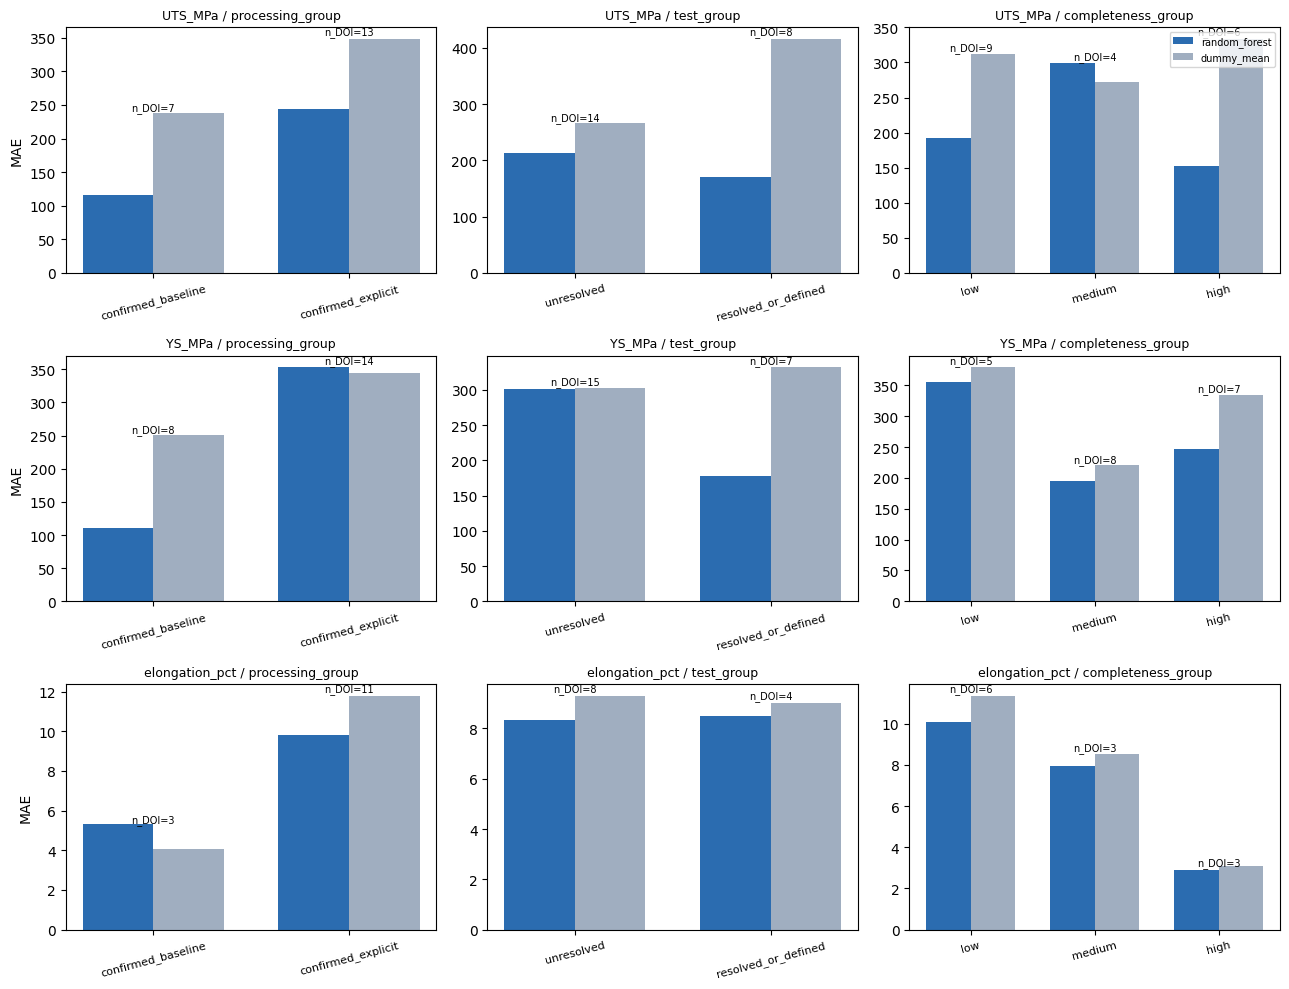

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for row_idx, target in enumerate(TARGETS):
    for col_idx, dim in enumerate(DIMENSIONS):
        ax = axes[row_idx, col_idx]
        rf_rows = rf_subgroup_table[(rf_subgroup_table["target"] == target) &
                                     (rf_subgroup_table["dimension"] == dim) &
                                     (rf_subgroup_table["model"] == "random_forest")]
        dummy_rows = rf_subgroup_table[(rf_subgroup_table["target"] == target) &
                                        (rf_subgroup_table["dimension"] == dim) &
                                        (rf_subgroup_table["model"] == "dummy_mean")]
        order = (["confirmed_baseline", "confirmed_explicit"] if dim == "processing_group" else
                 ["unresolved", "resolved_or_defined"] if dim == "test_group" else
                 ["low", "medium", "high"])
        rf_rows = rf_rows.set_index("group_value").reindex([g for g in order if g in rf_rows["group_value"].values or True]).dropna(how="all")
        x = np.arange(len(rf_rows))
        ax.bar(x - 0.18, rf_rows["MAE"], width=0.36, label="random_forest", color="#2b6cb0")
        dummy_vals = dummy_rows.set_index("group_value").reindex(rf_rows.index)["MAE"]
        ax.bar(x + 0.18, dummy_vals, width=0.36, label="dummy_mean", color="#a0aec0")
        for xi, (grp, n_doi) in enumerate(zip(rf_rows.index, rf_rows["n_DOI"])):
            ax.text(xi, max(rf_rows["MAE"].iloc[xi], dummy_vals.iloc[xi]) * 1.02, f"n_DOI={int(n_doi)}",
                    ha="center", fontsize=7)
        ax.set_xticks(x); ax.set_xticklabels(rf_rows.index, fontsize=8, rotation=15)
        ax.set_title(f"{target} / {dim}", fontsize=9)
        if col_idx == 0:
            ax.set_ylabel("MAE")
        if row_idx == 0 and col_idx == 2:
            ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## Output 4 — Gradient Boosting sensitivity check

Same three dimensions, Gradient Boosting only. `direction_agrees` states whether GB's lowest-error group within each target × dimension matches RF's — a broad-direction check, not a formal test.


In [9]:
gb_rows = []
for target in TARGETS:
    for dim in DIMENSIONS:
        rf_slice = rf_subgroup_table[(rf_subgroup_table["target"] == target) &
                                      (rf_subgroup_table["dimension"] == dim) &
                                      (rf_subgroup_table["model"] == "random_forest")]
        gb_oof = analysis_frames[target][analysis_frames[target]["model"] == "gradient_boosting"]
        gb_t = dim_table(gb_oof, dim, target, "gradient_boosting")

        rf_best = rf_slice.loc[rf_slice["MAE"].idxmin(), "group_value"] if len(rf_slice) else None
        gb_best = gb_t.loc[gb_t["MAE"].idxmin(), "group_value"] if len(gb_t) else None
        gb_t["rf_lowest_error_group"] = rf_best
        gb_t["gb_lowest_error_group"] = gb_best
        gb_t["direction_agrees"] = (rf_best == gb_best)
        gb_rows.append(gb_t)

gb_sensitivity_table = pd.concat(gb_rows, ignore_index=True)
gb_sensitivity_table

,target,dimension,model,group_value,n_obs,n_DOI,MAE,median_abs_error,support,rf_lowest_error_group,gb_lowest_error_group,direction_agrees
0,UTS_MPa,processing_group,gradient_boosting,confirmed_baseline,32,7,106.159788,63.500000,exploratory,confirmed_baseline,confirmed_baseline,True
1,UTS_MPa,processing_group,gradient_boosting,confirmed_explicit,62,13,252.949149,202.270020,supported_descriptive,confirmed_baseline,confirmed_baseline,True
2,UTS_MPa,test_group,gradient_boosting,resolved_or_defined,28,8,151.661751,81.923013,exploratory,resolved_or_defined,resolved_or_defined,True
3,UTS_MPa,test_group,gradient_boosting,unresolved,66,14,224.748961,166.825182,supported_descriptive,resolved_or_defined,resolved_or_defined,True
4,UTS_MPa,completeness_group,gradient_boosting,low,48,9,177.603801,164.230701,exploratory,high,high,True
5,UTS_MPa,completeness_group,gradient_boosting,medium,18,4,350.861446,233.662574,insufficient_support,high,high,True
6,UTS_MPa,completeness_group,gradient_boosting,high,28,6,151.409714,81.923013,exploratory,high,high,True
7,YS_MPa,processing_group,gradient_boosting,confirmed_baseline,34,8,108.657038,24.432640,exploratory,confirmed_baseline,confirmed_baseline,True
8,YS_MPa,processing_group,gradient_boosting,confirmed_explicit,61,14,345.782261,224.238028,supported_descriptive,confirmed_baseline,confirmed_baseline,True
9,YS_MPa,test_group,gradient_boosting,resolved_or_defined,27,7,200.195295,23.782640,exploratory,resolved_or_defined,resolved_or_defined,True


## Interpretation

For UTS_MPa (19 DOI total), the clearest pattern is on the processing dimension: `confirmed_baseline` observations have RF MAE 115 against `confirmed_explicit`'s 245 (`confirmed_explicit`, 13 DOI, reaches `supported_descriptive`; `confirmed_baseline`, 7 DOI, is only `exploratory`). That direction is the opposite of a naive "less-explicit processing information → worse predictions" expectation, and Gradient Boosting agrees. The completeness dimension shows no monotonic trend here — medium is worst, not low. RF beats the dummy reference in every subgroup.

For YS_MPa (20 DOI total), the same counter-intuitive processing direction repeats (`confirmed_baseline` MAE 110 against `confirmed_explicit`'s 353), and the test-condition direction also inverts naive expectation (`resolved_or_defined` MAE 178 against `unresolved`'s 301). But RF's advantage over the dummy reference is concentrated in exactly these smaller, better-performing subgroups — in the two larger subgroups (`confirmed_explicit`, `unresolved`) RF is roughly tied with, or slightly worse than, dummy, which is consistent with YS's near-zero pooled R² from Notebook 03. The completeness pattern is non-monotonic too, with medium lowest rather than high.

For elongation_pct (12 DOI total), every subgroup is `insufficient_support` or, at best, `exploratory` — no comparison reaches `supported_descriptive`. Composition completeness is the only dimension that even looks monotonic (low 10.1 → medium 7.9 → high 2.9), but the two better-completeness groups have only 3 DOI each, far below any threshold that would justify calling this a finding. RF's advantage over dummy is inconsistent across subgroups here too — worse than dummy in `confirmed_baseline`, better elsewhere.

Across all three targets, Gradient Boosting agrees with Random Forest on the lower-error group in all 21 target × dimension comparisons (100%), so the directions reported above aren't an artifact of one specific model. But "GB agrees with RF" isn't the same as "the difference is real" — most of these comparisons rest on well under 10 DOI per group, and none of the three dimensions shows a clean, monotonic, well-supported relationship with error across all three targets. The one dimension that does reach `supported_descriptive` on both sides of the comparison, in two targets (processing status, for both UTS and YS), shows *lower* error in the *less*-explicit-processing group — the opposite of a simple "more complete context → better predictions" story.

I'm not going to force that story: no consistent, well-supported relationship between contextual completeness and prediction error was found across all three targets and all three dimensions. The counter-intuitive processing-status direction is worth flagging for discussion as an observed association, but it isn't explained here — it's just as plausible that `confirmed_explicit` papers systematically report more compositionally diverse, harder-to-predict alloys, as that anything about processing status itself drives error. No causal claim, and no claim about the incremental predictive value of these fields, is made anywhere in this notebook.
